# 12 — Three questions: what the evidence says, net of what it costs

This notebook answers report v10's three questions with what notebooks 01–11 built, after the critique review of 21 October 2026: it lays out the registration ledger, prices the liquidity line the capital plan rests on, and (in later sections, once the v10 registration is committed) runs the four-arm challenger ladder, the reading and injection tests, the robustness checks and the partial forward test on realized 2025 data. Everything here is a post-registration extension of report v9 unless its section says it was registered first.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/success_criteria*.csv`, `results/registered_bridged/`, `results/registered_v7/`, `results/v9/` | every registered line as scored, never edited |
| in | `data/interim/scenario_state.npz`, `results/candidate_npv.csv` | the engines of notebook 11 (primary and held-out scenarios) |
| out | `results/v10/registration_ledger.csv`, `docs/registration_ledger.md` | the three-column ledger |
| out | `results/v10/credit_line_net.csv`, `results/v10/credit_line_sensitivity.csv` | book D by liquidity line, gross and net of financing; the break-even fee |
| out | `figures/F48_credit_line_net.*` | report figure |

*Execution order:* after notebook 11. Paths are relative to the repository root.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import challenge as ch, config, optimizer as opt, paths, plots, registration_ledger as rl, robustness as rb, whatif as wi

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "12_three_questions"
START = time.time()
R = paths.RESULTS
V10 = R / "v10"
V10.mkdir(exist_ok=True)
LEVEL = 0.95
print(f"loss variable: CVaR{LEVEL:.0%} of -NPV, the mean of the {opt.tail_count(2000, LEVEL)} worst of 2,000 held-out scenarios (optimizer.cvar)")

loss variable: CVaR95% of -NPV, the mean of the 100 worst of 2,000 held-out scenarios (optimizer.cvar)


## 1. The registration ledger

Every registered line (C1–C32) with its verdict as first scored, each correction made afterwards with its date, and its status now. A registered verdict is never re-scored: a correction adds a row. The C20–C24 lines were first scored on ERCOT prices bridged from PJM, so their registered verdict is that scoring and the observed-price verdict is their first correction; C21–C24 then carry the post-registration result on the corrected system, and C31 the two checks of decision #97.

In [2]:
ledger = rl.build()
counts = rl.write(ledger)
print(f"{counts['lines']} registered lines; {counts['corrected']} with a correction; {counts['verdict_changed']} correction rows whose verdict differs from the registered one")
ledger[ledger["correction"] != ""][["criterion", "line", "registered_verdict", "correction_date", "verdict_after", "status"]].drop_duplicates(["criterion", "line", "correction_date"])

78 registered lines; 17 with a correction; 3 correction rows whose verdict differs from the registered one


,criterion,line,registered_verdict,correction_date,verdict_after,status
54,C20,ERCOT log price +1 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
55,C20,Gas CC CF +1 m,PASS,2026-10-14,PASS,as registered: the observed-price scoring is the registered verdict
56,C20,Henry Hub log price +1 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
57,C20,Solar CF +1 m,PASS,2026-10-14,PASS,as registered: the observed-price scoring is the registered verdict
58,C20,WTI log price +1 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
59,C20,Wind CF +1 m,PASS,2026-10-14,PASS,as registered: the observed-price scoring is the registered verdict
60,C20,lease gas +12 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
61,C20,lease gas +3 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
62,C20,lease gas +6 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
63,C20,lease oil +12 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict


## 2. The credit line is not free

Report v9 said a $3.28B contingent construction line restores book D's value from $1.40B to $2.02B, as if the line cost nothing. A bank charges a commitment fee on what is not drawn and interest on what is. This section values book D by line size gross and net of that financing (`robustness.financing_cost`): the reserve is spent first in time order, the line after it; a plant whose cumulative draw passes the reserve draws the excess on the line in its construction year (two years before operation, ASSUMED) and repays it at operation; the fee runs on the undrawn line through the seven-year window. Two cases: the fee alone, and the fee with interest. The ATB capital costs already carry a construction-finance factor, so interest on the drawn part may double-count; the fee-only case is the clean lower bound of the cost and the fee-with-interest case the upper bound. Rates: fee 0.5% a year, interest 8% a year, discounted at the committee grid's 8% (ASSUMED; the sensitivity below spans 0.25–1% and 6–10%).

In [3]:
sel = wi.Engine(2000, "primary")
held = wi.Engine(2000, "held-out")
s = ch.Setting(sel, held, "committee")
x_D = np.asarray(s.x_model, int)
lease = np.ones(len(s.ids), bool)
lease[s.power_idx] = False
reserve = float((s.capex_p * s.p7)[x_D[s.power_idx] == 1].sum())
calls = rb.capital_calls(held.op_year, s.capex_p, x_D[s.power_idx], s.p7)
lease_value = s.A_h[:, lease] @ x_D[lease]


def book_value(line, fee, rate):
    """Book D's held-out totals with a line of the given size, net of its financing at the given fee and rate."""
    power = rb.funding_or_forfeit(s.A_h[:, s.power_idx], held.op_year, s.capex_p, s.carry_p, x_D[s.power_idx], reserve, line, s.priority, fee=fee, rate=rate)
    return lease_value + power


def scores_of(tot):
    return {"mean": float(tot.mean()), "cvar_loss": float(opt.cvar(-tot, LEVEL)), "metric": float(tot.mean() - opt.cvar(-tot, LEVEL))}


LINES = [("no line", 0.0), ("$0.5B line", 0.5e9), ("$1B line", 1e9), ("$2B line", 2e9), ("line at the 95th percentile of the excess", calls["excess_q95"]), ("unlimited (the static book)", np.inf)]
no_line = scores_of(book_value(0.0, 0.0, 0.0))
rows = []
for name, line in LINES:
    priced = np.isfinite(line) and line > 0
    g = scores_of(book_value(line if np.isfinite(line) else 1e12, 0.0, 0.0))
    f = scores_of(book_value(line, config.LINE_FEE, 0.0)) if priced else g
    fr = scores_of(book_value(line, config.LINE_FEE, config.LINE_RATE)) if priced else g
    be_fee = rb.breakeven_fee(lambda fee: scores_of(book_value(line, fee, 0.0))["metric"], no_line["metric"]) if priced else np.nan
    be_fee_rate = rb.breakeven_fee(lambda fee: scores_of(book_value(line, fee, config.LINE_RATE))["metric"], no_line["metric"]) if priced else np.nan
    rows.append({"liquidity": name, "line": line if np.isfinite(line) else np.nan, "mean_gross": g["mean"], "metric_gross": g["metric"], "cvar_loss_gross": g["cvar_loss"],
                 "mean_fee": f["mean"], "metric_fee": f["metric"], "mean_fee_rate": fr["mean"], "metric_fee_rate": fr["metric"], "cvar_loss_fee_rate": fr["cvar_loss"],
                 "financing_mean_fee": g["mean"] - f["mean"], "financing_mean_fee_rate": g["mean"] - fr["mean"], "breakeven_fee_only": be_fee, "breakeven_fee_with_rate": be_fee_rate})
credit = pd.DataFrame(rows)
credit.to_csv(V10 / "credit_line_net.csv", index=False)
q95 = credit.set_index("liquidity").loc["line at the 95th percentile of the excess"]
print(f"book D, held-out, registered metric ($B): no line {no_line['metric'] / 1e9:.3f}; 95th-percentile line gross {q95['metric_gross'] / 1e9:.3f}, "
      f"fee only {q95['metric_fee'] / 1e9:.3f}, fee and interest {q95['metric_fee_rate'] / 1e9:.3f}; expected value gross {q95['mean_gross'] / 1e9:.3f}, "
      f"fee and interest {q95['mean_fee_rate'] / 1e9:.3f}; break-even fee, fee only {q95['breakeven_fee_only']:.4f}, with interest {q95['breakeven_fee_with_rate']}; {time.time() - START:.0f} s")
(credit.set_index("liquidity")[["line", "mean_gross", "metric_gross", "mean_fee", "metric_fee", "mean_fee_rate", "metric_fee_rate", "financing_mean_fee_rate"]] / 1e9).round(3)

book D, held-out, registered metric ($B): no line 0.862; 95th-percentile line gross 0.995, fee only 0.835, fee and interest 0.659; expected value gross 2.017, fee and interest 1.863; break-even fee, fee only 0.0041, with interest nan; 40 s


,line,mean_gross,metric_gross,mean_fee,metric_fee,mean_fee_rate,metric_fee_rate,financing_mean_fee_rate
liquidity,,,,,,,,
no line,0.000,1.402,0.862,1.402,0.862,1.402,0.862,0.000
$0.5B line,0.500,1.687,0.719,1.675,0.694,1.672,0.685,0.015
$1B line,1.000,1.721,0.758,1.695,0.706,1.691,0.695,0.030
$2B line,2.000,1.953,0.897,1.905,0.802,1.847,0.657,0.106
line at the 95th percentile of the excess,3.281,2.017,0.995,1.937,0.835,1.863,0.659,0.155
unlimited (the static book),NaN,2.052,1.032,2.052,1.032,2.052,1.032,0.000


In [4]:
sens = []
for fee in (0.0025, 0.005, 0.01):
    for rate in (0.0, 0.06, 0.08, 0.10):
        sc = scores_of(book_value(calls["excess_q95"], fee, rate))
        sens.append({"fee": fee, "rate": rate, **sc, "metric_minus_no_line": sc["metric"] - no_line["metric"]})
sensitivity = pd.DataFrame(sens)
sensitivity.to_csv(V10 / "credit_line_sensitivity.csv", index=False)
print(f"the 95th-percentile line beats no line on the metric in {int((sensitivity['metric_minus_no_line'] > 0).sum())} of {len(sensitivity)} fee-rate settings")
(sensitivity.pivot(index="fee", columns="rate", values="metric") / 1e9).round(3)

the 95th-percentile line beats no line on the metric in 1 of 12 fee-rate settings


rate,0.00,0.06,0.08,0.10
fee,,,,
0.0025,0.915,0.785,0.739,0.692
0.0050,0.835,0.705,0.659,0.613
0.0100,0.674,0.545,0.500,0.453


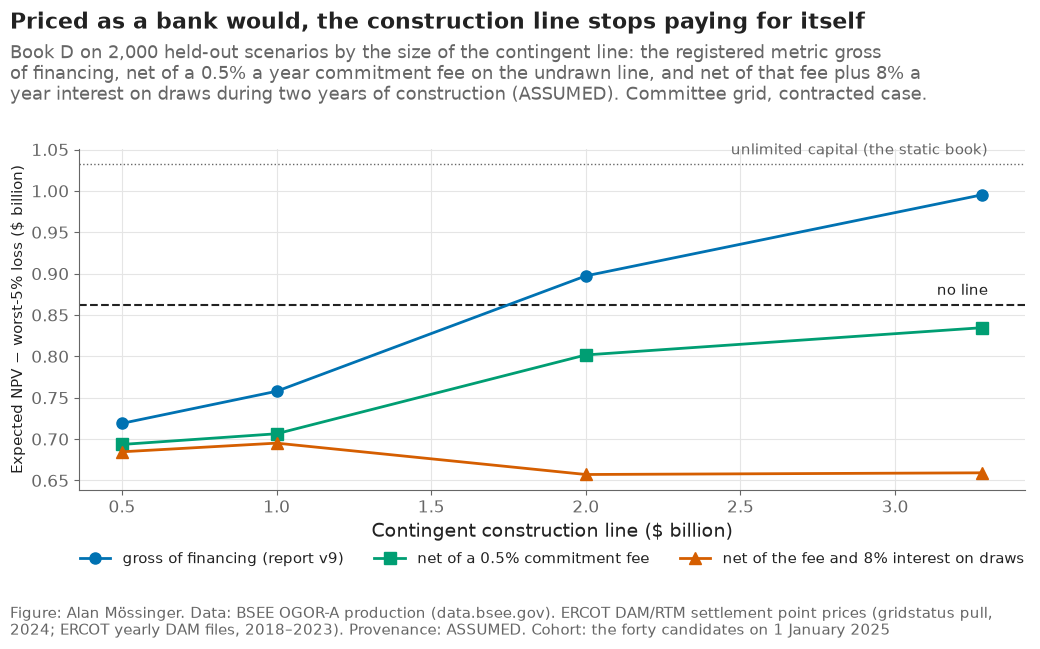

In [5]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sized = credit[credit["line"].notna() & (credit["line"] > 0)].sort_values("line")
ax.axhline(no_line["metric"] / 1e9, color=plots.INK, lw=1.5, ls="--")
ax.text(3.3, no_line["metric"] / 1e9 + 0.012, "no line", fontsize=11, color=plots.INK, ha="right")
unl = credit.set_index("liquidity").loc["unlimited (the static book)", "metric_gross"] / 1e9
ax.axhline(unl, color=plots.MUTED, lw=1, ls=":")
ax.text(3.3, unl + 0.012, "unlimited capital (the static book)", fontsize=11, color=plots.MUTED, ha="right")
for col, label, color, marker in (("metric_gross", "gross of financing (report v9)", "#0072B2", "o"), ("metric_fee", "net of a 0.5% commitment fee", "#009E73", "s"),
                                  ("metric_fee_rate", "net of the fee and 8% interest on draws", "#D55E00", "^")):
    ax.plot(sized["line"] / 1e9, sized[col] / 1e9, marker=marker, color=color, lw=2, ms=8, label=label)
ax.set_xlabel("Contingent construction line ($ billion)")
ax.set_ylabel("Expected NPV − worst-5% loss ($ billion)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=11, frameon=False)
plots.finish(fig, "Priced as a bank would, the construction line stops paying for itself",
             "Book D on 2,000 held-out scenarios by the size of the contingent line: the registered metric gross of financing, net of a 0.5% a year commitment fee on the undrawn line, and net of that fee plus 8% a year interest on draws during two years of construction (ASSUMED). Committee grid, contracted case.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="ASSUMED")
plots.save_fig(fig, "F48_credit_line_net", "Book D's registered metric by liquidity line, gross and net of the line's financing cost, with the break-even fee.", NOTEBOOK)
plt.show()

**Reading this.** Gross of financing, as report v9 valued it, a contingent line raises book D's registered metric only once it is large: $0.5B and $1B lines score *below* no line (0.72 and 0.76 against 0.86) because they let the book fund a few construction calls whose outcomes are the risky ones, and the 95th-percentile line of $3.28B reaches 0.995 against 1.032 with unlimited capital. Priced as a bank would, the line stops paying for itself: a 0.5% commitment fee alone takes the $3.28B line to 0.835, below no line, and the fee breaks even at 0.41% a year; with 8% interest on the draws as well, the line is worth 0.659 and no fee breaks even. On expected value the line still pays — $1.86B net against $1.40B with no line — so the cost falls on the tail: the fee is paid in full in exactly the scenarios in which nothing is built and the leases earn least. The ATB capital costs already carry a construction-finance factor, so the fee-only case is the clean lower bound of the cost and the fee-with-interest case the upper bound. For the committee this changes the memo's sentence: the line is worth having for its expected value, not for the registered risk metric, and its price has to be negotiated below about 0.4% a year before it improves that metric at all.

## Checks

In [6]:
checks = pd.DataFrame([
    ("the ledger holds every criterion C1-C32 and 78 registered lines", bool({f"C{i}" for i in range(1, 33)} <= set(ledger["criterion"]) and counts["lines"] == 78)),
    ("a free line reproduces report v9's gross values", bool(np.isclose(credit.set_index("liquidity").loc["no line", "mean_gross"], pd.read_csv(R / "v8" / "robustness_capital_calls.csv").set_index("liquidity").loc["no line", "mean"], rtol=1e-6))),
    ("financing lowers every priced line's value", bool((credit.loc[credit["line"].fillna(0) > 0, "metric_fee_rate"] < credit.loc[credit["line"].fillna(0) > 0, "metric_gross"]).all())),
    ("F48 saved", (paths.FIGURES / "F48_credit_line_net.png").exists()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(V10 / "checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]

run time 0.7 min


,check,result
0,the ledger holds every criterion C1-C32 and 78 registered lines,PASS
1,a free line reproduces report v9's gross values,PASS
2,financing lowers every priced line's value,PASS
3,F48 saved,PASS


## Takeaways

- The registration ledger joins every registered line (78 of C1–C32) with its corrections: 17 lines carry one, and 3 correction rows change the verdict (C21, C23 and C24 on the observed prices or the corrected system); the registered verdicts stand.
- The loss variable behind every "worst-5% loss" is the CVaR95 of −NPV, the mean of the 100 worst of 2,000 held-out scenarios; active queue requests are right-censored, never counted as failed.
- The contingent construction line is not free: at the 95th percentile of the excess ($3.28B) it lifts book D's expected value to $1.86B net of a 0.5% fee and 8% interest (from $1.40B with no line), but lowers the registered metric to 0.66 from 0.86; the fee alone breaks even at 0.41% a year, and with interest no fee does. The memo's "a line restores $2.02B" was gross.

**What goes to the report.** `results/v10/registration_ledger.csv`, `credit_line_net.csv`, `credit_line_sensitivity.csv` through `src/report_numbers.py`; figure F48.